# 04 - Rede neural (MLP) de classificação: protocolo e baseline

**Problema:** prever `has_heart_disease` (0 = sem doença, 1 = com doença), classificação **binária**, com as
mesmas 30 features da Atividade 2.

Este notebook segue o mesmo protocolo do notebook 03 (mesma divisão, padronização ajustada só no treino) e:
1. analisa o desbalanceamento das classes;
2. define a camada de saída e a função de perda e justifica as escolhas;
3. treina a configuração de referência (baseline) com 5 sementes e salva o checkpoint do baseline.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src.config import MODELS, SEMENTES, ler_dataset, indices_split, preparar, salvar_fig, salvar_tabela
from src.models import criar_modelo, n_parametros
from src.train import BASELINE, executar, prever, salvar_checkpoint

torch.set_num_threads(1)
PROBLEMA = "classificacao"

## 1. Divisão e desbalanceamento

In [2]:
df = ler_dataset(PROBLEMA)
idx_tr, idx_val, idx_te, idx_tr_total = indices_split(df)
y = df["has_heart_disease"]
divisao = pd.DataFrame({
    "conjunto": ["treino", "validação", "teste"],
    "n": [len(idx_tr), len(idx_val), len(idx_te)],
    "positivos (com doença)": [int(y.loc[i].sum()) for i in (idx_tr, idx_val, idx_te)],
    "% positivos": [100 * y.loc[i].mean() for i in (idx_tr, idx_val, idx_te)],
})
salvar_tabela(divisao, "divisao_classificacao")
divisao.round(2)

,conjunto,n,positivos (com doença),% positivos
0,treino,5760,1746,30.31
1,validação,1440,436,30.28
2,teste,1800,545,30.28


A estratificação mantém ~30,3% de positivos nos três conjuntos. A razão negativos/positivos no treino é
0,697/0,303 ≈ **2,30**. Com esse desbalanceamento, um classificador que sempre responde "sem doença" teria
accuracy de ~0,70 e recall zero; por isso a **métrica principal é o F1 da classe positiva** (a mesma da
Atividade 2), acompanhada de recall, precision, ROC-AUC e PR-AUC.

## 2. Camada de saída e função de perda

- **Saída:** 1 neurônio linear que produz o **logit** $z$ (sem sigmoide). A probabilidade de doença é
  $p = \sigma(z)$, calculada com `torch.sigmoid` só na inferência e no cálculo de ROC/PR.
- **Perda:** `nn.BCEWithLogitsLoss`, a entropia cruzada binária aplicada direto sobre o logit. Ela junta a
  sigmoide e o logaritmo numa expressão estável (truque log-sum-exp). Usar `Sigmoid` + `BCELoss` em separado
  satura em $p = 0$ ou $1$ e gera $\log(0)$. Para um problema binário, 1 saída + BCE é equivalente a 2 saídas
  + softmax + `CrossEntropyLoss`, com metade dos pesos na última camada.
- **Desbalanceamento:** o baseline usa a BCE sem peso. O efeito de `pos_weight` (peso da classe positiva na
  perda) é avaliado no estudo de hiperparâmetros com os valores 1; 1,5; 2,3 (razão neg/pos) e 3,5.

In [3]:
dados = preparar(PROBLEMA)
modelo = criar_modelo(BASELINE, len(dados.features))
print(modelo)
print("Parâmetros treináveis:", n_parametros(modelo))
with torch.no_grad():
    z = modelo(torch.tensor(dados.X_val[:5]))
print("Saída bruta (logits) da rede ainda não treinada:", z.squeeze(1).numpy().round(3))
print("Probabilidades (sigmoide):", torch.sigmoid(z).squeeze(1).numpy().round(3))

MLP(
  (net): Sequential(
    (0): Linear(in_features=30, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Parâmetros treináveis: 2081
Saída bruta (logits) da rede ainda não treinada: [-0.134 -0.112 -0.295 -0.19  -0.096]
Probabilidades (sigmoide): [0.467 0.472 0.427 0.453 0.476]


## 3. Treino do baseline (5 sementes)

In [4]:
resultados, historicos, modelos = [], [], []
for s in SEMENTES:
    r, h, m = executar(BASELINE, dados, s, retornar_modelo=True)
    resultados.append(r); historicos.append(h); modelos.append(m)
res = pd.DataFrame(resultados)
cols = ["seed", "melhor_epoca", "epocas_executadas", "tempo_treino_s", "treino_F1", "val_F1",
        "val_Precision", "val_Recall", "val_ROC-AUC", "val_PR-AUC"]
res[cols].round(4)

,seed,melhor_epoca,epocas_executadas,tempo_treino_s,treino_F1,val_F1,val_Precision,val_Recall,val_ROC-AUC,val_PR-AUC
0,0,7,27,3.0074,0.8559,0.8213,0.8673,0.7798,0.9493,0.9095
1,1,5,25,2.7701,0.8507,0.8177,0.8568,0.7821,0.9472,0.9065
2,2,6,26,2.8768,0.8536,0.8244,0.8603,0.7913,0.9503,0.9113
3,3,6,26,2.8718,0.8506,0.8278,0.8650,0.7936,0.9484,0.9098
4,4,6,26,2.8755,0.8553,0.8253,0.8441,0.8073,0.9485,0.9099


In [5]:
resumo = res[cols[1:]].agg(["mean", "std"]).T
resumo.columns = ["média", "desvio"]
salvar_tabela(res, "baseline_classificacao_sementes")
resumo.round(4)

,média,desvio
melhor_epoca,6.0000,0.7071
epocas_executadas,26.0000,0.7071
tempo_treino_s,2.8803,0.0843
treino_F1,0.8532,0.0025
val_F1,0.8233,0.0039
val_Precision,0.8587,0.0091
val_Recall,0.7908,0.0109
val_ROC-AUC,0.9487,0.0012
val_PR-AUC,0.9094,0.0018


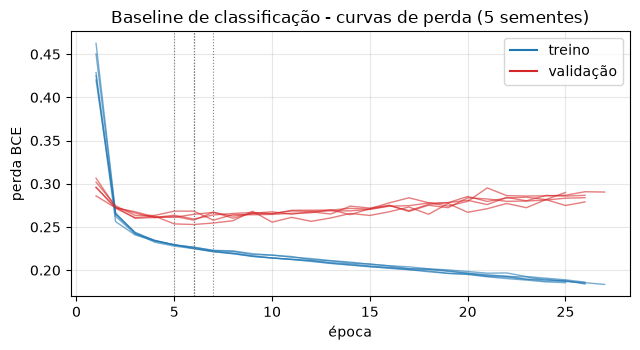

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for h in historicos:
    ax.plot(range(1, len(h["treino"]) + 1), h["treino"], color="#1f77b4", alpha=0.6, lw=1)
    ax.plot(range(1, len(h["val"]) + 1), h["val"], color="#d62728", alpha=0.6, lw=1)
for r in resultados:
    ax.axvline(r["melhor_epoca"], color="gray", ls=":", lw=0.8)
ax.plot([], [], color="#1f77b4", label="treino"); ax.plot([], [], color="#d62728", label="validação")
ax.set(xlabel="época", ylabel="perda BCE", title="Baseline de classificação - curvas de perda (5 sementes)")
ax.legend(); ax.grid(alpha=0.3); fig.tight_layout()
salvar_fig("baseline_curvas_classificacao")
plt.show()

Mesmo padrão da regressão: a perda de validação chega ao mínimo nas primeiras épocas (melhor época 5 a 7) e depois sobe enquanto a de
treino segue caindo (início de overfitting). O early stopping restaura o melhor estado.

**Distribuição das probabilidades na validação:** com a BCE sem peso, a rede aprende probabilidades próximas das
frequências reais; o limiar 0,5 é o ponto de partida, e a escolha do limiar na validação é feita no notebook 05
para o modelo final.

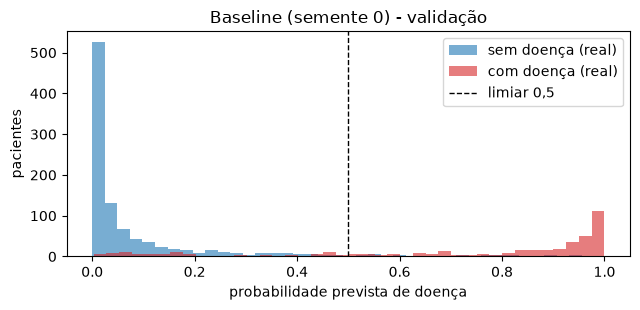

In [7]:
i0 = 0
prob = 1 / (1 + np.exp(-prever(modelos[i0], dados.X_val)))
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.hist(prob[dados.y_val_orig == 0], bins=40, alpha=0.6, label="sem doença (real)", color="#1f77b4")
ax.hist(prob[dados.y_val_orig == 1], bins=40, alpha=0.6, label="com doença (real)", color="#d62728")
ax.axvline(0.5, color="k", ls="--", lw=1, label="limiar 0,5")
ax.set(xlabel="probabilidade prevista de doença", ylabel="pacientes", title="Baseline (semente 0) - validação")
ax.legend(); fig.tight_layout()
salvar_fig("baseline_probabilidades_classificacao")
plt.show()

## 4. Checkpoint do baseline

Salva-se a semente de maior F1 de validação, com limiar 0,5 (o baseline não tem ajuste de limiar).

In [8]:
i_melhor = int(res["val_F1"].idxmax())
print("Semente escolhida:", SEMENTES[i_melhor], "| F1 de validação:", round(res.loc[i_melhor, "val_F1"], 4))
salvar_checkpoint(modelos[i_melhor], BASELINE, dados, MODELS / "baseline_classificacao.pt", limiar=0.5,
                  extras={"seed": SEMENTES[i_melhor], "historico": historicos[i_melhor]})
print("Salvo em", MODELS / "baseline_classificacao.pt")

Semente escolhida: 3 | F1 de validação: 0.8278
Salvo em C:\Users\Halyson\Documents\Projetos\Faculdade\IA-MINE\atividade_03\models\baseline_classificacao.pt
